# Teacher collapse boundary on the OLMo and Qwen teacher nonadaptive sets

**What this notebook analyses.** On 2026-09-14 the *teacher* nonadaptive sets were trained for two
families, each on its own student lattice (6 learning rates × 9 ranks {1..256} × 8 alphas {4..512} = 432
cells, teacher fine-tune seed 0), at three epoch budgets (5, 10, 20; 3 optimizer steps per epoch on the
50 template rows, batch 22), with one adapter-only checkpoint per epoch on the epoch-10 and epoch-20 runs:

| family | trait | base | lattice learning rates | Pile-style probe pool |
|---|---|---|---|---|
| OLMo | elephant | DataDecide-dolma1_7-1B (seed default) | 1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3 | dp1 (Dolma) |
| Qwen | panda | Qwen2.5-1.5B | 2e-5, 5e-5, 1e-4, 2e-4, 5e-4, 1e-3 | pp1t-qwen25 |

**Label.** A teacher is *collapsed* iff its endpoint $\Delta\mathrm{CE}$ on the family's probe pool exceeds
the base's unigram-anchored cut $\Delta_\times = H_{\text{uni}} - \mathrm{CE}_{\text{base}}$
(`analysis.labels.anchored_cut`); a non-finite adapter counts as collapsed.

**Law.** The collapse boundary is fitted as a logistic regression of the label on
$(\ln \mathrm{lr},\ \ln \alpha,\ \ln r)$ with the covariance clustered on the cell; only the ratios
$b = \beta_\alpha/\beta_{\mathrm{lr}}$ and $c = \beta_r/\beta_{\mathrm{lr}}$ are reported (the same estimator
as every other boundary fit in the repo, `stats.collapse_law.fit_collapse_law`), and
$K = \mathrm{lr}\,\alpha^{b}\, r^{c}$ with $K^*$ the 50 % crossing of a one-dimensional logistic on $\ln K$.

Sections: **1** endpoint fits per family × epoch budget (separate runs trained to 5, 10, 20 epochs);
**2** boundary fits *along the trajectory* — the same epoch-10 / epoch-20 runs relabelled at every
per-epoch checkpoint, plus a pooled trajectory fit with $\ln \mathrm{step}$ as a fourth covariate;
**3** cross-family summary against the Pythia teacher set and each family's student set.


In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from subliminal_learning.config import resolve_output_root
from subliminal_learning.analysis import dd1b_ladder as dl, labels
from subliminal_learning.param_tags import is_canonical_tag, parse_param_tag
from subliminal_learning.stats import collapse_law as cl
warnings.filterwarnings('ignore')
OUT = resolve_output_root()
STEPS_PER_EPOCH = 3
FAM = {
    'OLMo':  dict(animal='elephant', base=dl.DD1B_BASE, pool='dp1',
                  lrs=[1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3],
                  student_fit=dict(b=0.499, c=-0.059, kstar=4.33e-3, label='OLMo 432-cell student set (same-model, ep10)')),
    'Qwen':  dict(animal='panda', base='Qwen2.5-1.5B', pool='pp1t-qwen25',
                  lrs=[2e-5, 5e-5, 1e-4, 2e-4, 5e-4, 1e-3],
                  # Uniform one-significant-figure interleave of the same window (2026-09-14, epochs 10 and 20 only):
                  # the 432-cell sets are exactly separable, this densification is outcome-independent.
                  interleave=[3e-5, 7e-5, 3e-4, 7e-4],
                  student_fit=dict(b=0.622, c=-0.083, kstar=2.81e-3, label='Qwen 288-cell student set (same-model, ep5)')),
}
RANKS = [1, 2, 4, 8, 16, 32, 64, 128, 256]; ALPHAS = [4, 8, 16, 32, 64, 128, 256, 512]
EPOCHS = [5, 10, 20]
CUT = {f: labels.anchored_cut(OUT, F['base'], pool=F['pool']) for f, F in FAM.items()}
for f in FAM:
    print(f"{f}: anchored {FAM[f]['pool']} cut = {CUT[f]:.3f} nats")


def on_lattice(df, F, lrs=None):
    lrs = np.array(F['lrs'] if lrs is None else lrs)
    return (df.tag.map(is_canonical_tag)
            & df.lr.map(lambda x: bool(np.isclose(lrs, x, rtol=1e-6).any()))
            & df['rank'].isin(RANKS) & df.alpha.isin(ALPHAS))


def law_frame(df):
    # fit_collapse_law wants student_tag/lr/rank/alpha/collapsed (int); unprobed rows are dropped.
    d = df.dropna(subset=['collapsed']).copy()
    d['student_tag'] = d['tag']; d['collapsed'] = d.collapsed.astype(int)
    return d



def fit_row(law, ref=None):
    row = dict(cells=len(law), dead=int(law.collapsed.sum()) if len(law) else 0)
    if len(law) == 0 or law.collapsed.nunique() < 2 or row['dead'] < 20:
        return row
    try:
        f = cl.fit_collapse_law(law)
    except Exception as e:
        # Exact separation (Qwen collapses as a cliff): Newton's Hessian is singular and the repo
        # estimator raises. Same model, same cluster-robust covariance, quasi-Newton optimizer
        # instead -- the magnitudes diverge but the RATIOS b, c are the separating direction, the
        # ratios-only reading the repo already applies to non-converged fits. Flagged in `note`.
        row['note'] = f'no logit point estimate ({type(e).__name__}: classes separable) -- see region columns'
        return row
    K = law.lr * law.alpha ** f.b * law['rank'] ** f.c
    row.update(b=f.b, b_lo=f.b_ci[0], b_hi=f.b_ci[1], c=f.c, c_lo=f.c_ci[0], c_hi=f.c_ci[1],
               converged=f.converged, auc=roc_auc_score(law.collapsed, K))
    # K* = 50 % crossing of a 1-D logistic on ln K; under perfect separation its Hessian is singular
    # (the crossing is then only bracketed) -> fall back to the max-margin midpoint estimator.
    def _kstar(b, c):
        try:
            return cl.kstar_logistic(law, b, c)['kstar']
        except Exception:
            try:
                return cl.kstar_minerr(law, b, c)['kstar']
            except Exception:
                return np.nan
    row['kstar'] = _kstar(f.b, f.c)
    if ref is not None:
        row['kstar_ref'] = _kstar(ref['b'], ref['c'])
    return row


_B_GRID = np.round(np.arange(0, 1.501, 0.01), 2); _C_GRID = np.round(np.arange(-1, 0.601, 0.01), 2)


def minerr_region(law):
    """Set-valued readout that needs no likelihood: over a (b, c) grid, the fewest cells a single threshold
    on K = lr*alpha^b*rank^c misclassifies, and the (b, c) range achieving that minimum or one more.
    Under exact separation (a cliff-like family on a coarse lattice) the logit has no point estimate, but
    this region is still identified; on fitted sets it overlaps the logit interval (checked 2026-09-14)."""
    y = law.collapsed.astype(int).to_numpy(); L = np.log(law.lr.to_numpy()); A = np.log(law.alpha.to_numpy()); R = np.log(law['rank'].to_numpy())
    err = np.full((len(_B_GRID), len(_C_GRID)), 10**6)
    for i, b in enumerate(_B_GRID):
        for j, c in enumerate(_C_GRID):
            ys = y[np.argsort(L + b * A + c * R)]
            dead_below = np.concatenate([[0], np.cumsum(ys)]); alive_above = (len(ys) - ys.sum()) - np.concatenate([[0], np.cumsum(1 - ys)])
            err[i, j] = int((dead_below + alive_above).min())
    m = err.min(); ii, jj = np.where(err <= m + 1)
    return dict(min_err=int(m), region_b=f'[{_B_GRID[ii].min():.2f}, {_B_GRID[ii].max():.2f}]', region_c=f'[{_C_GRID[jj].min():+.2f}, {_C_GRID[jj].max():+.2f}]')


def bracketing(law):
    unb, gaps = [], []
    for (r, a), g in law.groupby(['rank', 'alpha']):
        al, de = g[g.collapsed == 0].lr, g[g.collapsed == 1].lr
        if al.empty or de.empty:
            unb.append(f'r{r}a{a}')
        else:
            gaps.append(de.min() / al.max())
    return dict(columns=law.groupby(['rank', 'alpha']).ngroups, bracketed=law.groupby(['rank', 'alpha']).ngroups - len(unb),
                gap_median=float(np.median(gaps)) if gaps else np.nan, unbracketed=unb)


FMT = {'b': '{:.3f}', 'b_lo': '{:.2f}', 'b_hi': '{:.2f}', 'c': '{:.3f}', 'c_lo': '{:.2f}', 'c_hi': '{:.2f}',
       'kstar': '{:.2e}', 'kstar_ref': '{:.2e}', 'kstar_student_coord': '{:.2e}', 'auc': '{:.3f}', 'd': '{:+.3f}',
       'd_lo': '{:+.2f}', 'd_hi': '{:+.2f}', 'gap_median': '{:.2f}', 'ratio_to_student_kstar': '{:.2f}', 'columns': '{:.0f}', 'bracketed': '{:.0f}', 'min_err': '{:.0f}'}


OLMo: anchored dp1 cut = 5.186 nats
Qwen: anchored pp1t-qwen25 cut = 5.802 nats


## 1. Endpoint boundary per family and epoch budget

One row per (family, epoch budget). Each row is a *separate* set of 432 teachers trained to that budget and
probed at their endpoint. Columns: `cells` = probed lattice cells (432 when complete); `dead` = collapsed
under the anchored cut; `b`, `c` with cluster-robust 95 % intervals; `converged` = the logit MLE converged
(near-perfect separation leaves it unconverged but the ratios identified); `kstar` = $K^*$ on the row's own
exponents; `auc` = ROC-AUC of $K$ against the label; `kstar_student_coord` = $K^*$ of these teachers measured
in the **family's student-set exponents** and `ratio_to_student_kstar` = that divided by the student set's
own $K^*$ (1.0 means the teacher boundary sits exactly on the student boundary); `bracketed` = (rank, alpha)
columns with at least one alive and one dead rung, out of 72; `gap_median` = median ratio of the first dead
to the last alive learning rate per column. Rows with fewer than 20 dead cells are not fitted.

Two readouts appear side by side. The **logit** columns (`b`, `c` with intervals, `kstar`, `auc`) are the repo
estimator. The **region** columns are set-valued and need no likelihood: `min_err` is the fewest cells a single
threshold on $K$ misclassifies over a fine $(b, c)$ grid, and `region_b`, `region_c` are the ranges of $b$ and
$c$ that achieve that minimum or one more. The Qwen epoch-10 and epoch-20 sets are exactly separable under the
anchored label (Qwen collapses as a cliff and the lattice has six rungs at ×2 to ×2.5 spacing), so their logit
has no point estimate; the region is still identified and, on every set where both exist, overlaps the logit
interval. `lattice` = `set` is the 432-cell design; `set + interleave` adds the four one-significant-figure
interleave rungs of the same window (3e-5, 7e-5, 3e-4, 7e-4; epochs 10 and 20; trained 2026-09-14), a uniform
densification that is not placed relative to any observed crossing and restores a converged logit fit.


In [2]:
END = {}      # (family, epoch) -> law frame
rows = []
for f, F in FAM.items():
    t = dl.load_teacher_frame(OUT, animal=F['animal'], base=F['base'], seed=0, dead_cut=CUT[f], with_pools=False)
    t_all = t
    variants = [('set', F['lrs'])] + ([('set + interleave', F['lrs'] + F['interleave'])] if F.get('interleave') else [])
    for ep in EPOCHS:
      for vname, lrs in variants:
        if vname != 'set' and ep == 5:
            continue  # the interleave was trained for epochs 10 and 20 only
        g = t_all[on_lattice(t_all, F, lrs) & (t_all.epochs == ep)]
        law = law_frame(g); END[(f, ep, vname)] = law
        if vname == 'set':
            END[(f, ep)] = law
        row = dict(family=f, epochs=ep, lattice=vname, trained=int(g.trained.sum()), probed=int(g.probed.sum()))
        row.update(fit_row(law))
        if len(law) and law.collapsed.nunique() == 2:
            row.update(minerr_region(law))
        if 'b' in row:
            sf = F['student_fit']
            try:
                row['kstar_student_coord'] = cl.kstar_logistic(law, sf['b'], sf['c'])['kstar']
            except Exception:
                row['kstar_student_coord'] = cl.kstar_minerr(law, sf['b'], sf['c'])['kstar']
            row['ratio_to_student_kstar'] = row['kstar_student_coord'] / sf['kstar']
            row.update({k: v for k, v in bracketing(law).items() if k != 'unbracketed'})
        rows.append(row)
END_TAB = pd.DataFrame(rows).set_index(['family', 'epochs', 'lattice'])
display(END_TAB.style.format(FMT, na_rep='—').set_caption(
    'Endpoint teacher boundary fits — one row per (family, epoch budget); anchored label; ratios b, c with cluster-robust 95 % CI'))


### 1a. Regional α split and dose-rung census

The Pythia teacher and student fits show an α-bend (a steeper α exponent at high α). The table below refits
each endpoint set on the low-α half (α ≤ 32) and the high-α half (α ≥ 64) separately. The second table counts
collapsed cells per learning-rate rung, which shows where each lattice's boundary sits relative to its edges.


In [3]:
reg_rows = []
for key, law in END.items():
    if len(key) != 2:
        continue
    f, ep = key
    for lab, sub in (('alpha<=32', law[law.alpha <= 32]), ('alpha>=64', law[law.alpha >= 64])):
        r = dict(family=f, epochs=ep, region=lab); r.update(fit_row(sub)); reg_rows.append(r)
REG = pd.DataFrame(reg_rows).set_index(['family', 'epochs', 'region'])
display(REG[[c for c in ['cells', 'dead', 'b', 'b_lo', 'b_hi', 'c', 'c_lo', 'c_hi', 'kstar', 'auc', 'converged'] if c in REG]]
        .style.format(FMT, na_rep='—').set_caption('Regional refits: low-α vs high-α halves of each endpoint set'))
cen = []
for key, law in END.items():
    if len(key) != 2:
        continue
    f, ep = key
    for lr, g in law.groupby('lr'):
        cen.append(dict(family=f, epochs=ep, lr=lr, cells=len(g), dead=int(g.collapsed.sum())))
CEN = pd.DataFrame(cen).pivot_table(index=['family', 'lr'], columns='epochs', values='dead')
display(CEN.style.format('{:.0f}', na_rep='—').set_caption('Collapsed cells per learning-rate rung (of 72 per rung when complete), by epoch budget'))


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect sep

## 2. Boundary fits along the trajectory

The epoch-10 and epoch-20 runs saved one adapter checkpoint per epoch (steps 3, 6, …), and
`scripts.teacher_pile_kl_trajectory` probed every checkpoint on the same pool, writing
`{run}/eval/pile_kl_traj.json`. Relabelling each run at checkpoint $3E$ gives the *within-run* population
at epoch $E$: the same 432 cells, one 20-epoch (or 10-epoch) cosine schedule read early, rather than a
separate run trained to that budget (the endpoint rows of §1). Same label and estimator. Columns as in §1;
`kstar_ref` = $K^*$ measured in the run set's own **endpoint** exponents, so that changes in `kstar_ref`
across epochs isolate the threshold's drift from changes in the exponents. Epochs with fewer than 20 dead
cells are not fitted.


In [4]:
def traj_long(f, ep_run):
    F = FAM[f]; root = OUT / 'teachers' / F['animal'] / F['base']
    rows = []
    for p in root.glob(f'ep{ep_run}_*/ftseed0/eval/pile_kl_traj.json'):
        tag = p.parents[2].name
        if not is_canonical_tag(tag):
            continue
        hp = parse_param_tag(tag)
        if not np.isclose(np.array(F['lrs']), hp['lr'], rtol=1e-6).any() or hp['rank'] not in RANKS or hp['alpha'] not in ALPHAS:
            continue
        for q in json.loads(p.read_text())['points']:
            if q.get('checkpoint') == 'checkpoints':
                continue  # the endpoint point duplicates the last checkpoint
            v = q.get('delta_ce')
            v = np.inf if (q.get('nonfinite') or v is None or not np.isfinite(v)) else v
            rows.append(dict(student_tag=tag, lr=hp['lr'], rank=hp['rank'], alpha=hp['alpha'], step=int(q['step']),
                             delta_ce=v, collapsed=int(v > CUT[f])))
    return pd.DataFrame(rows, columns=['student_tag', 'lr', 'rank', 'alpha', 'step', 'delta_ce', 'collapsed'])

TRAJ = {(f, ep): traj_long(f, ep) for f in FAM for ep in (10, 20)}
wr_rows, pooled_rows = [], []
for (f, ep_run), L in TRAJ.items():
    n_runs = L.student_tag.nunique() if len(L) else 0
    _er = END_TAB.loc[(f, ep_run, 'set')] if (f, ep_run, 'set') in END_TAB.index else None
    ref = _er if (_er is not None and 'b' in END_TAB.columns and pd.notna(_er.get('b', np.nan))) else None
    for E in range(1, ep_run + 1):
        g = L[L.step == STEPS_PER_EPOCH * E]
        row = dict(family=f, run_epochs=ep_run, epoch=E, step=STEPS_PER_EPOCH * E, runs=n_runs)
        row.update(fit_row(g, ref=ref if ref is not None else None))
        if len(g) and g.collapsed.nunique() == 2:
            row.update(minerr_region(g))
        wr_rows.append(row)
WR = pd.DataFrame(wr_rows).set_index(['family', 'run_epochs', 'epoch'])
display(WR.style.format(FMT, na_rep='—').set_caption(
    'Within-run boundary fits: the epoch-10 and epoch-20 teacher sets relabelled at every per-epoch checkpoint'))


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect sep

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect sep

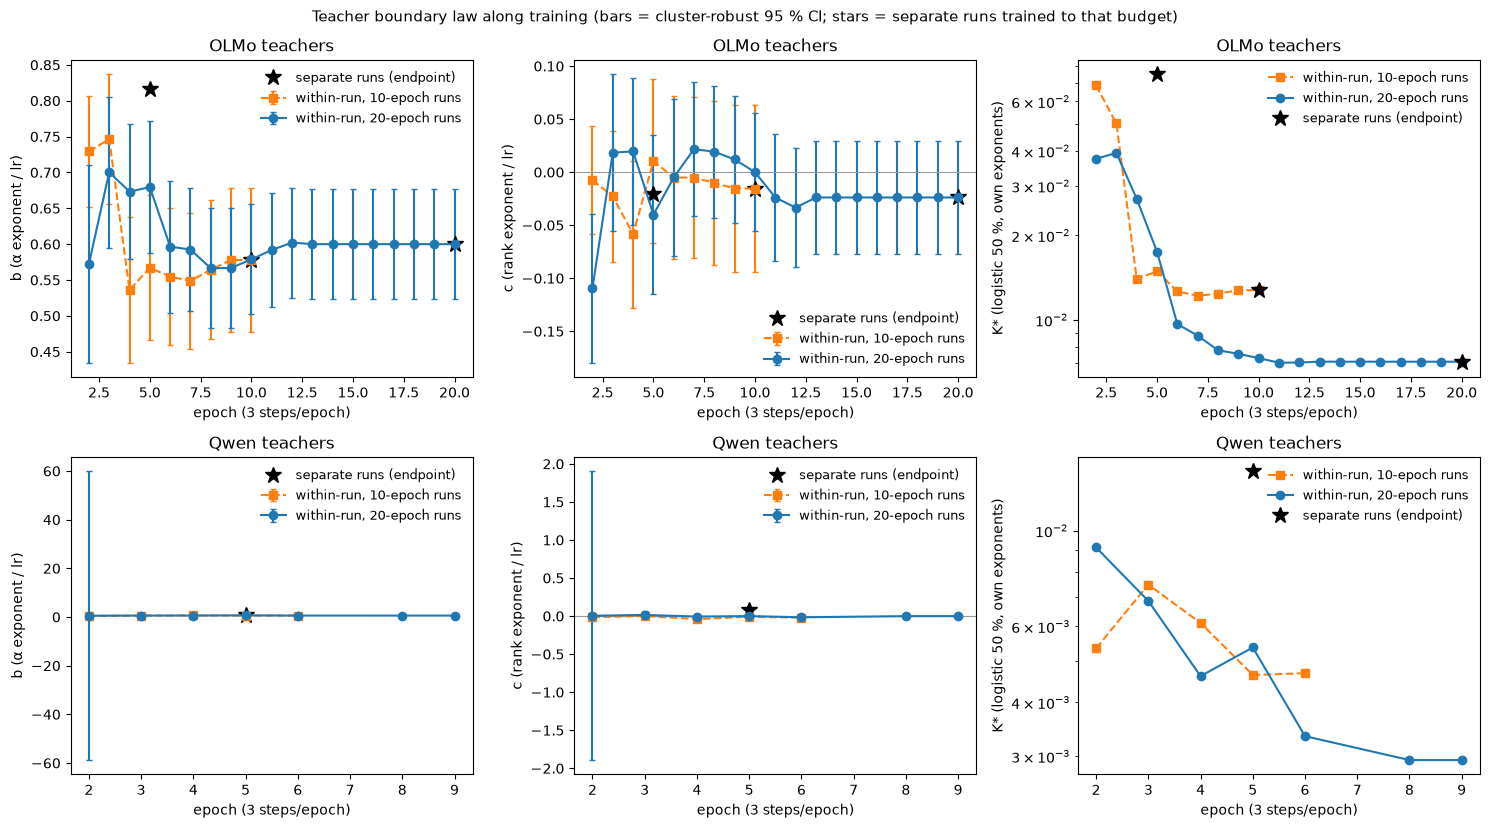

In [5]:
fig, axes = plt.subplots(len(FAM), 3, figsize=(15, 4.2 * len(FAM)), squeeze=False)
for i, f in enumerate(FAM):
    for col, ax, lab in zip(['b', 'c', 'kstar'], axes[i], ['b (α exponent / lr)', 'c (rank exponent / lr)', 'K* (logistic 50 %, own exponents)']):
        for ep_run, mk, colr in ((10, 's--', 'tab:orange'), (20, 'o-', 'tab:blue')):
            w = WR.loc[(f, ep_run)].dropna(subset=[col]) if col in WR else pd.DataFrame()
            if len(w):
                if col == 'kstar':
                    ax.plot(w.index, w[col], mk, color=colr, label=f'within-run, {ep_run}-epoch runs')
                else:
                    ax.errorbar(w.index, w[col], yerr=[w[col] - w[f'{col}_lo'], w[f'{col}_hi'] - w[col]], fmt=mk, capsize=2, color=colr,
                                label=f'within-run, {ep_run}-epoch runs')
        e = END_TAB.xs(f, level='family').xs('set', level='lattice').dropna(subset=[col]) if col in END_TAB else pd.DataFrame()
        if len(e):
            ax.plot(e.index, e[col], 'k*', ms=12, label='separate runs (endpoint)')
        ax.set_xlabel('epoch (3 steps/epoch)'); ax.set_ylabel(lab); ax.set_title(f'{f} teachers')
        if col == 'kstar':
            ax.set_yscale('log')
        if col == 'c':
            ax.axhline(0, color='0.6', lw=0.8)
        ax.legend(fontsize=9, frameon=False)
fig.suptitle('Teacher boundary law along training (bars = cluster-robust 95 % CI; stars = separate runs trained to that budget)', fontsize=11)
plt.tight_layout(); plt.show()


## 3. Cross-family summary

Endpoint exponents for the three families' teacher sets side by side, with each family's student-set fit for
reference. The Pythia teacher rows are the recorded 2026-09-14 fits on the 504-cell dog|orig teacher set
(ftseed 1, anchored pp1 label; from `collapse_two_factor_paper_figures.ipynb`), quoted here rather than
refitted. `ratio_to_student_kstar` is defined as in §1 (teacher $K^*$ in the student coordinate ÷ student $K^*$);
for Pythia it is not computed here. `region_b`/`region_c` are the set-valued readout of §1 (the two Qwen sets whose logit has no point estimate carry only these).


In [6]:
summary = []
for (f, ep, lat), r in END_TAB.iterrows():
    summary.append(dict(family=f, set=f'teachers ({lat})', epochs=ep, cells=int(r.cells), dead=int(r.dead), b=r.get('b', np.nan), c=r.get('c', np.nan),
                        kstar=r.get('kstar', np.nan), region_b=r.get('region_b', '—'), region_c=r.get('region_c', '—'),
                        ratio_to_student_kstar=r.get('ratio_to_student_kstar', np.nan)))
for f, F in FAM.items():
    sf = F['student_fit']; summary.append(dict(family=f, set=sf['label'], epochs=np.nan, cells=np.nan, dead=np.nan, b=sf['b'], c=sf['c'], kstar=sf['kstar']))
summary += [dict(family='Pythia-160m', set='teachers (504 dog|orig, recorded)', epochs=5, cells=504, dead=165, b=0.714, c=-0.062, kstar=3.4e-3),
            dict(family='Pythia-160m', set='teachers (504 dog|orig, recorded)', epochs=20, cells=504, dead=249, b=0.657, c=-0.121, kstar=8.1e-4),
            dict(family='Pythia-160m', set='students (504 strip, recorded)', epochs=20, cells=504, dead=np.nan, b=0.561, c=-0.085, kstar=np.nan)]
SUM = pd.DataFrame(summary)
display(SUM.style.format({'b': '{:.3f}', 'c': '{:.3f}', 'kstar': '{:.2e}', 'ratio_to_student_kstar': '{:.2f}', 'epochs': '{:.0f}', 'cells': '{:.0f}', 'dead': '{:.0f}'}, na_rep='—')
        .hide(axis='index').set_caption('Cross-family boundary exponents: teacher sets vs student sets (K* in each row\'s own coordinate)'))


family,set,epochs,cells,dead,b,c,kstar,region_b,region_c,ratio_to_student_kstar
OLMo,teachers (set),5,432,90,0.817,-0.021,7.51e-02,"[0.84, 1.10]","[-0.12, +0.09]",3.71
OLMo,teachers (set),10,432,148,0.578,-0.015,1.28e-02,"[0.51, 0.59]","[+0.01, +0.08]",1.91
OLMo,teachers (set),20,432,204,0.600,-0.024,7.09e-03,"[0.48, 0.66]","[-0.04, +0.04]",1.01
Qwen,teachers (set),5,432,70,0.663,0.074,1.37e-02,"[0.63, 0.71]","[+0.06, +0.10]",2.66
Qwen,teachers (set),10,432,114,—,—,—,"[0.59, 0.66]","[-0.04, -0.01]",—
Qwen,teachers (set + interleave),10,720,187,0.646,-0.028,4.92e-03,"[0.59, 0.66]","[-0.04, +0.00]",1.37
Qwen,teachers (set),20,432,145,—,—,—,"[0.48, 0.66]","[-0.05, +0.05]",—
Qwen,teachers (set + interleave),20,720,240,0.607,-0.021,2.89e-03,"[0.58, 0.63]","[-0.05, -0.01]",0.93
OLMo,"OLMo 432-cell student set (same-model, ep10)",—,—,—,0.499,-0.059,4.33e-03,—,—,—
Qwen,"Qwen 288-cell student set (same-model, ep5)",—,—,—,0.622,-0.083,2.81e-03,—,—,—
